Model input size: 160
Using saved test split: 100 pairs


I0000 00:00:1792652594.619329   37722 service.cc:153] XLA service 0x73e8441c1660 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792652594.619395   37722 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1792652594.701348   37722 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792652595.016471   37722 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1792652614.221337   37722 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



   VALIDATION REPORT  (mean +- std over images)
 dice        : 0.8507 +- 0.2088
 iou         : 0.7808 +- 0.2274
 precision   : 0.8700 +- 0.2113
 recall      : 0.8739 +- 0.2142
 specificity : 0.9703 +- 0.0672
 accuracy    : 0.9554 +- 0.0699


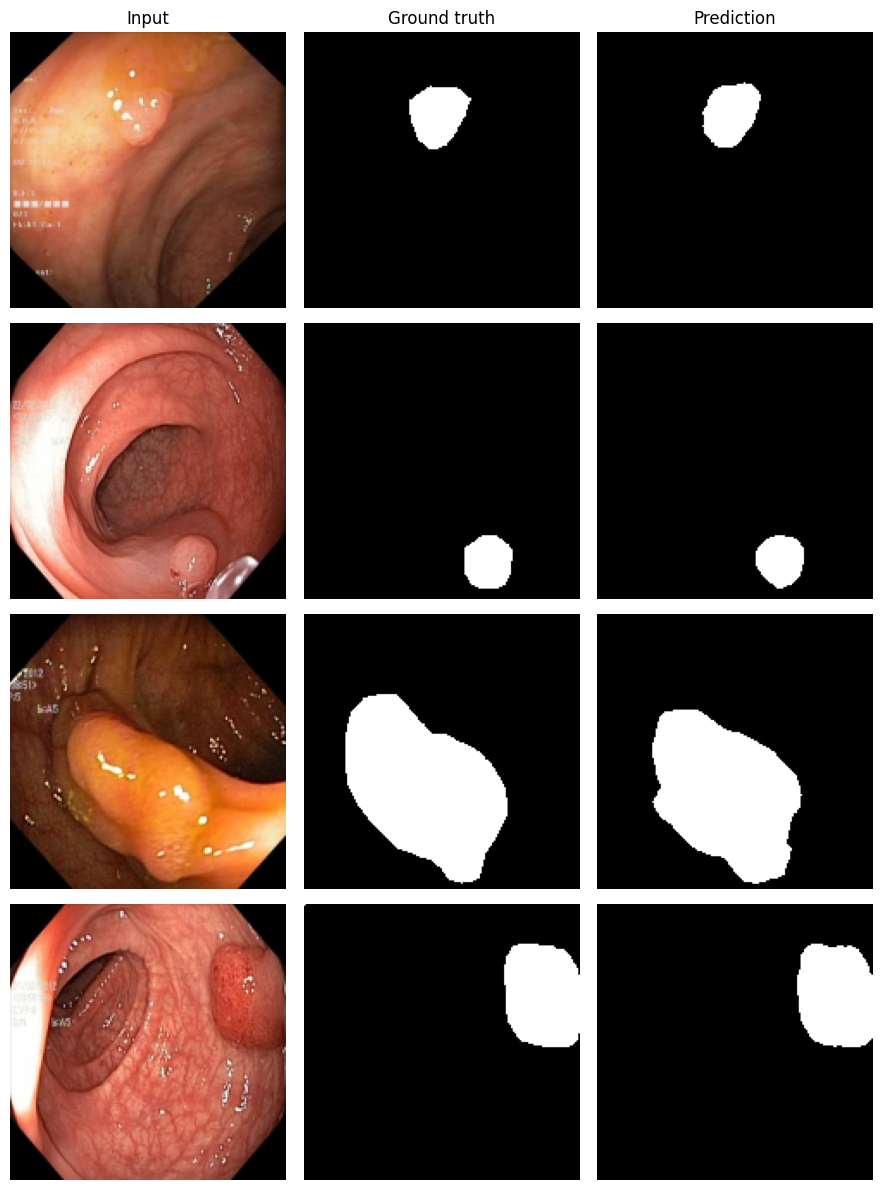

preview saved -> /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/external_validation_previewA.png


In [2]:
import os, json, glob
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ============================ CONFIG ================================
MODEL_PATH = r"/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/micromodel_v3_compressed_train.keras"
SPLITS_JSON = MODEL_PATH[:-len(".keras")] + "_splits.json"

# Option A (default): held-out test split of Kvasir-SEG, taken from the saved splits file
# Option B: true external validation, set USE_SPLIT_FILE = False and point to another dataset
USE_SPLIT_FILE = True
EXTERNAL_IMG_DIR  = r"/path/to/other_dataset/images"
EXTERNAL_MASK_DIR = r"/path/to/other_dataset/masks"

IMG_INTERP = cv2.INTER_AREA          # must match training
N_PREVIEW = 4
OUT_PNG = os.path.join(os.path.dirname(MODEL_PATH), "external_validation_previewA.png")
# ====================================================================

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
KEYS = ["dice", "iou", "precision", "recall", "specificity", "accuracy"]

for g in tf.config.list_physical_devices("GPU"):
    try: tf.config.experimental.set_memory_growth(g, True)
    except Exception: pass


def get_pairs():
    if USE_SPLIT_FILE:
        with open(SPLITS_JSON) as f:
            pairs = json.load(f)["test"]
        print(f"Using saved test split: {len(pairs)} pairs")
        return pairs
    masks = {os.path.splitext(f)[0]: f for f in os.listdir(EXTERNAL_MASK_DIR) if f.lower().endswith(EXTS)}
    pairs = [(os.path.join(EXTERNAL_IMG_DIR, f), os.path.join(EXTERNAL_MASK_DIR, masks[os.path.splitext(f)[0]]))
             for f in sorted(os.listdir(EXTERNAL_IMG_DIR))
             if f.lower().endswith(EXTS) and os.path.splitext(f)[0] in masks]
    assert pairs, "No image/mask pairs found - check paths and filenames."
    print(f"Using external dataset: {len(pairs)} pairs")
    return pairs


def read_pair(ip, mp, size):
    img = cv2.imread(ip); msk = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    assert img is not None and msk is not None, f"Cannot read: {ip} / {mp}"
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size), interpolation=IMG_INTERP)
    msk = cv2.resize(msk, (size, size), interpolation=cv2.INTER_NEAREST)
    return img, (msk > 127).astype(np.uint8)


def batch_metrics(pred, gt, eps=1e-7):
    p = pred.reshape(len(gt), -1).astype(np.float64); g = gt.reshape(len(gt), -1).astype(np.float64)
    tp = (p * g).sum(1); fp = (p * (1 - g)).sum(1); fn = ((1 - p) * g).sum(1); tn = ((1 - p) * (1 - g)).sum(1)
    return {"dice": (2 * tp + eps) / (2 * tp + fp + fn + eps),
            "iou": (tp + eps) / (tp + fp + fn + eps),
            "precision": (tp + eps) / (tp + fp + eps),
            "recall": (tp + eps) / (tp + fn + eps),
            "specificity": (tn + eps) / (tn + fp + eps),
            "accuracy": (tp + tn) / (tp + tn + fp + fn)}


# --- load model (no compile needed: we compute the metrics ourselves) ---
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
size = int(model.input_shape[1])
print("Model input size:", size)

pairs = get_pairs()
per = {k: [] for k in KEYS}
preview = []

for s in range(0, len(pairs), 64):
    data = [read_pair(ip, mp, size) for ip, mp in pairs[s:s + 64]]
    imgs = np.stack([d[0] for d in data]); gts = np.stack([d[1] for d in data])
    x = (imgs.astype(np.float32) / 255.0 - MEAN) / STD
    logits = model.predict(x, batch_size=32, verbose=0)[..., 0]          # model outputs logits
    probs = 1.0 / (1.0 + np.exp(-np.clip(logits, -50, 50)))
    m = batch_metrics(probs > 0.5, gts)
    for k in KEYS: per[k].append(m[k])
    if len(preview) < N_PREVIEW:
        for i in range(min(N_PREVIEW - len(preview), len(imgs))):
            preview.append((imgs[i], gts[i], probs[i] > 0.5))

per = {k: np.concatenate(v) for k, v in per.items()}

print("\n" + "=" * 60)
print("   VALIDATION REPORT  (mean +- std over images)")
print("=" * 60)
for k in KEYS:
    print(f" {k:<12}: {per[k].mean():.4f} +- {per[k].std():.4f}")
print("=" * 60)

# --- visual preview ---
fig, axs = plt.subplots(len(preview), 3, figsize=(9, 3 * len(preview)))
axs = np.atleast_2d(axs)
for r, (im, gt, pr) in enumerate(preview):
    for c, (a, cm, t) in enumerate([(im, None, "Input"), (gt, "gray", "Ground truth"), (pr, "gray", "Prediction")]):
        axs[r, c].imshow(a, cmap=cm); axs[r, c].axis("off")
        if r == 0: axs[r, c].set_title(t)
plt.tight_layout()
plt.savefig(OUT_PNG, dpi=200)
plt.show()
print("preview saved ->", OUT_PNG)

Model input size: 160
Using saved test split: 100 pairs

   VALIDATION REPORT  (mean +- std over images)
 dice        : 0.8507 +- 0.2088
 iou         : 0.7808 +- 0.2274
 precision   : 0.8700 +- 0.2113
 recall      : 0.8739 +- 0.2142
 specificity : 0.9703 +- 0.0672
 accuracy    : 0.9554 +- 0.0699
explaining image 1/4 ...
explaining image 2/4 ...
explaining image 3/4 ...
explaining image 4/4 ...


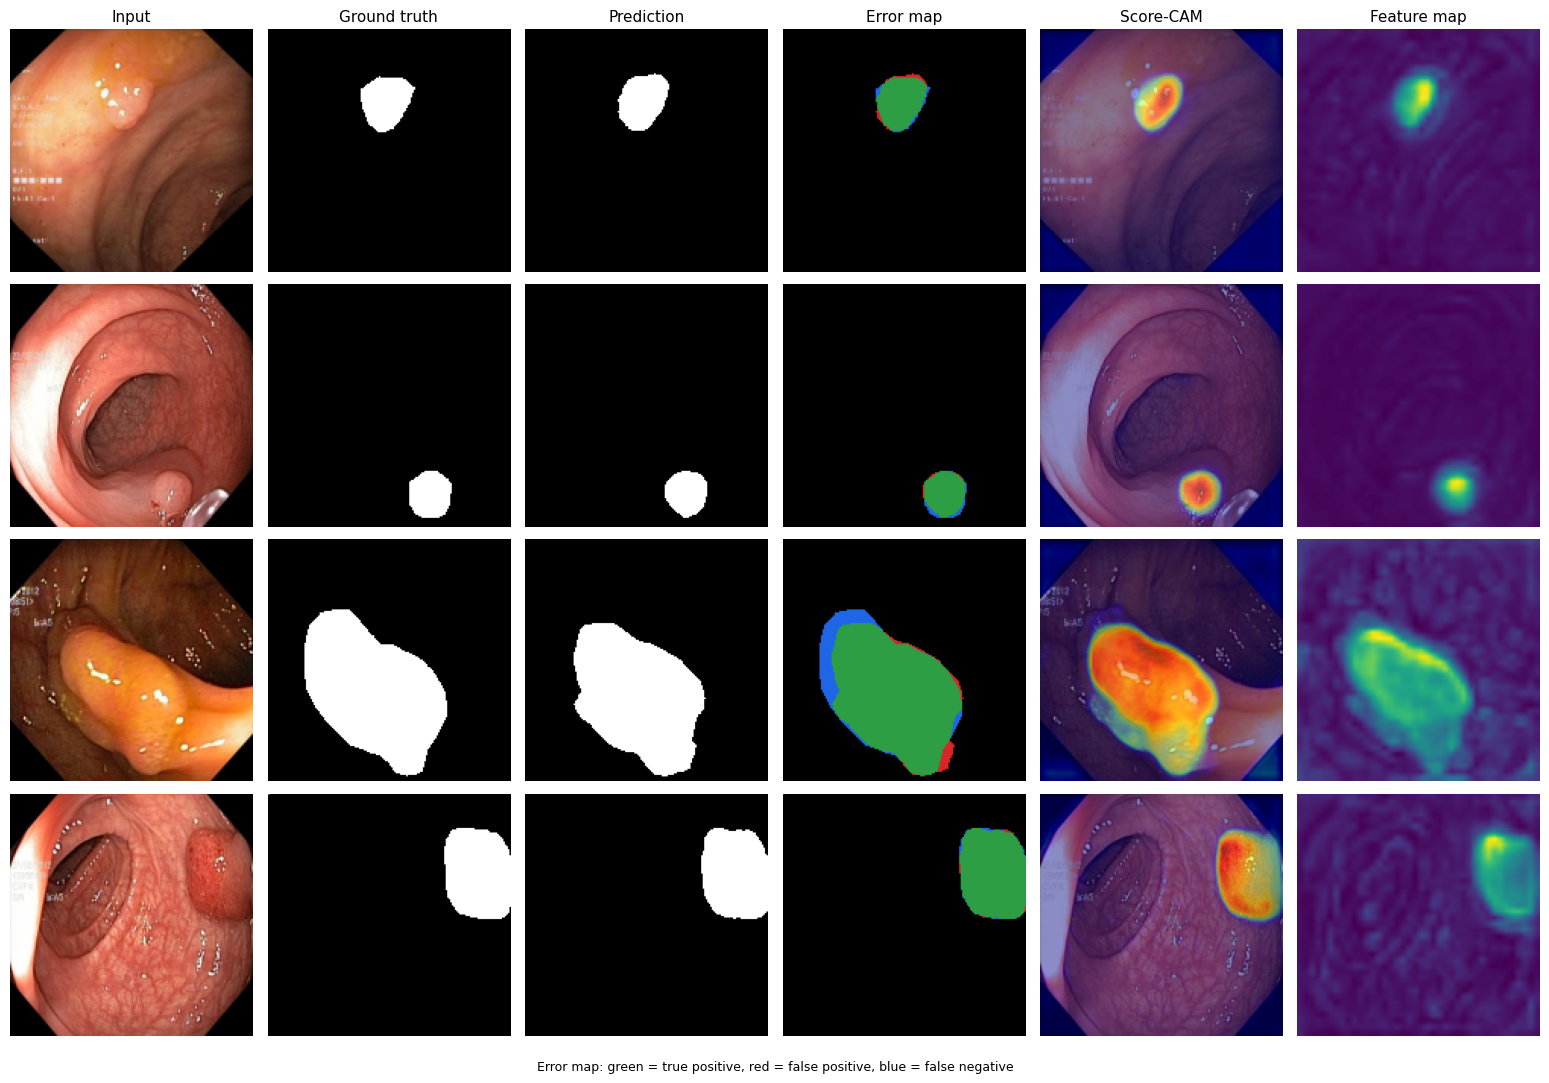

preview saved -> /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/external_validation_previewA.png


In [3]:
import os, json
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ============================ CONFIG ================================
MODEL_PATH = r"/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/micromodel_v3_compressed_train.keras"
SPLITS_JSON = MODEL_PATH[:-len(".keras")] + "_splits.json"

# Option A (default): held-out test split of Kvasir-SEG, taken from the saved splits file
# Option B: true external validation, set USE_SPLIT_FILE = False and point to another dataset
USE_SPLIT_FILE = True
EXTERNAL_IMG_DIR  = r"/path/to/other_dataset/images"
EXTERNAL_MASK_DIR = r"/path/to/other_dataset/masks"

IMG_INTERP = cv2.INTER_AREA          # must match training
N_PREVIEW = 4
CAM_LAYER = "dec1_out"               # layer used by Score-CAM (last decoder block, 32 channels)
FEATURE_LAYER = "dec2_out"           # layer shown in the Feature-map column (64 channels)
OUT_PNG = os.path.join(os.path.dirname(MODEL_PATH), "external_validation_previewA.png")
# ====================================================================

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
KEYS = ["dice", "iou", "precision", "recall", "specificity", "accuracy"]

for g in tf.config.list_physical_devices("GPU"):
    try: tf.config.experimental.set_memory_growth(g, True)
    except Exception: pass


def get_pairs():
    if USE_SPLIT_FILE:
        with open(SPLITS_JSON) as f:
            pairs = json.load(f)["test"]
        print(f"Using saved test split: {len(pairs)} pairs")
        return pairs
    masks = {os.path.splitext(f)[0]: f for f in os.listdir(EXTERNAL_MASK_DIR) if f.lower().endswith(EXTS)}
    pairs = [(os.path.join(EXTERNAL_IMG_DIR, f), os.path.join(EXTERNAL_MASK_DIR, masks[os.path.splitext(f)[0]]))
             for f in sorted(os.listdir(EXTERNAL_IMG_DIR))
             if f.lower().endswith(EXTS) and os.path.splitext(f)[0] in masks]
    assert pairs, "No image/mask pairs found - check paths and filenames."
    print(f"Using external dataset: {len(pairs)} pairs")
    return pairs


def read_pair(ip, mp, size):
    img = cv2.imread(ip); msk = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    assert img is not None and msk is not None, f"Cannot read: {ip} / {mp}"
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size), interpolation=IMG_INTERP)
    msk = cv2.resize(msk, (size, size), interpolation=cv2.INTER_NEAREST)
    return img, (msk > 127).astype(np.uint8)


def batch_metrics(pred, gt, eps=1e-7):
    p = pred.reshape(len(gt), -1).astype(np.float64); g = gt.reshape(len(gt), -1).astype(np.float64)
    tp = (p * g).sum(1); fp = (p * (1 - g)).sum(1); fn = ((1 - p) * g).sum(1); tn = ((1 - p) * (1 - g)).sum(1)
    return {"dice": (2 * tp + eps) / (2 * tp + fp + fn + eps),
            "iou": (tp + eps) / (tp + fp + fn + eps),
            "precision": (tp + eps) / (tp + fp + eps),
            "recall": (tp + eps) / (tp + fn + eps),
            "specificity": (tn + eps) / (tn + fp + eps),
            "accuracy": (tp + tn) / (tp + tn + fp + fn)}


# ----------------------- explanation helpers -----------------------
def to_input(img01):
    """img01: float32 in [0,1], shape (...,H,W,3) -> normalised network input."""
    return (img01 - MEAN) / STD


def minmax(a, eps=1e-8):
    return (a - a.min()) / (a.max() - a.min() + eps)


def error_map(gt, pred):
    """green = true positive, red = false positive, blue = false negative."""
    gt, pred = gt.astype(bool), pred.astype(bool)
    err = np.zeros((*gt.shape, 3), dtype=np.float32)
    err[gt & pred] = (0.18, 0.62, 0.27)
    err[~gt & pred] = (0.85, 0.15, 0.15)
    err[gt & ~pred] = (0.12, 0.40, 0.90)
    return err


def score_cam(model, extractor, img_u8, pred_mask, size):
    """Score-CAM for the predicted polyp region.
    Each activation channel becomes a soft mask on the input; the channel's weight is
    how much it raises the model's mean polyp probability inside the predicted region
    compared with a black image. No gradients are used."""
    img01 = img_u8.astype(np.float32) / 255.0
    acts = extractor.predict(to_input(img01)[None], verbose=0)[0][0]               # (h, w, K)
    up = tf.image.resize(acts[None], (size, size), method="bilinear")[0].numpy()   # (H, W, K)
    mn, mx = up.min((0, 1), keepdims=True), up.max((0, 1), keepdims=True)
    masks = np.transpose((up - mn) / (mx - mn + 1e-8), (2, 0, 1))[..., None]       # (K, H, W, 1)

    region = pred_mask.astype(np.float32)
    if region.sum() == 0:                                  # nothing predicted: use the whole image
        region = np.ones_like(region)

    def region_score(x):
        logits = model.predict(x, batch_size=64, verbose=0)[..., 0]
        probs = 1.0 / (1.0 + np.exp(-np.clip(logits, -50, 50)))
        return (probs * region).sum((1, 2)) / (region.sum() + 1e-8)

    base = region_score(to_input(np.zeros((1, size, size, 3), dtype=np.float32)))[0]
    gain = region_score(to_input(img01[None] * masks)) - base       # confidence increase per channel
    w = minmax(gain) if gain.max() > gain.min() else np.ones_like(gain)
    w = w / (w.sum() + 1e-8)
    cam = np.maximum((up * w[None, None, :]).sum(-1), 0)
    return minmax(cam)


def overlay(img_u8, cam, alpha=0.45):
    heat = plt.get_cmap("jet")(cam)[..., :3].astype(np.float32)
    return np.clip((1 - alpha) * (img_u8.astype(np.float32) / 255.0) + alpha * heat, 0, 1)


def feature_map(feat, size):
    """Channel-mean activation of an intermediate layer, upsampled for display."""
    fm = feat.mean(-1)
    fm = tf.image.resize(fm[None, ..., None], (size, size), method="bilinear")[0, ..., 0].numpy()
    return minmax(fm)


# --- load model (no compile needed: we compute the metrics ourselves) ---
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
size = int(model.input_shape[1])
print("Model input size:", size)

names = [l.name for l in model.layers]
for n in (CAM_LAYER, FEATURE_LAYER):
    assert n in names, f"Layer '{n}' not found. Available *_out layers: {[x for x in names if x.endswith('_out')]}"
extractor = tf.keras.Model(model.input, [model.get_layer(CAM_LAYER).output,
                                         model.get_layer(FEATURE_LAYER).output])

pairs = get_pairs()
per = {k: [] for k in KEYS}
preview = []

for s in range(0, len(pairs), 64):
    data = [read_pair(ip, mp, size) for ip, mp in pairs[s:s + 64]]
    imgs = np.stack([d[0] for d in data]); gts = np.stack([d[1] for d in data])
    x = to_input(imgs.astype(np.float32) / 255.0)
    logits = model.predict(x, batch_size=32, verbose=0)[..., 0]          # model outputs logits
    probs = 1.0 / (1.0 + np.exp(-np.clip(logits, -50, 50)))
    m = batch_metrics(probs > 0.5, gts)
    for k in KEYS: per[k].append(m[k])
    if len(preview) < N_PREVIEW:
        for i in range(min(N_PREVIEW - len(preview), len(imgs))):
            preview.append((imgs[i], gts[i], probs[i] > 0.5))

per = {k: np.concatenate(v) for k, v in per.items()}

print("\n" + "=" * 60)
print("   VALIDATION REPORT  (mean +- std over images)")
print("=" * 60)
for k in KEYS:
    print(f" {k:<12}: {per[k].mean():.4f} +- {per[k].std():.4f}")
print("=" * 60)

# --- visual preview: 6 columns ---
titles = ["Input", "Ground truth", "Prediction", "Error map", "Score-CAM", "Feature map"]
fig, axs = plt.subplots(len(preview), 6, figsize=(15.6, 2.6 * len(preview) + 0.4))
axs = np.atleast_2d(axs)

for r, (im, gt, pr) in enumerate(preview):
    print(f"explaining image {r + 1}/{len(preview)} ...")
    cam = score_cam(model, extractor, im, pr, size)
    feat = extractor.predict(to_input(im.astype(np.float32) / 255.0)[None], verbose=0)[1][0]
    panels = [(im, None), (gt, "gray"), (pr, "gray"),
              (error_map(gt, pr), None), (overlay(im, cam), None),
              (feature_map(feat, size), "viridis")]
    for c, (a, cm) in enumerate(panels):
        axs[r, c].imshow(a, cmap=cm); axs[r, c].axis("off")
        if r == 0: axs[r, c].set_title(titles[c], fontsize=11)

fig.text(0.5, 0.005, "Error map: green = true positive, red = false positive, blue = false negative",
         ha="center", fontsize=9)
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig(OUT_PNG, dpi=200)
plt.show()
print("preview saved ->", OUT_PNG)